In [3]:
%pip install pandas numpy matplotlib seaborn openpyxl

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.6 MB 6.4 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.6 MB 4.9 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.6 MB 4.9 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.6 MB 5.9 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.6 MB 6.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.6 MB 5.6 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.6 MB 5.5 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.6 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 5.3 MB/s  0:00:01
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ----- ---------------------------------- 1.8/12.6 MB 9.1 MB/s eta 0:00:02
   ---------- ----------------------------- 3.1/12.6 MB 7.9 MB/s eta 0:00:02
   ----------------- -----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
print("Hello")

Hello


In [5]:
# Load the dataset
df = pd.read_excel("Data/Dataset for Data Analytics.xlsx")

# Display the first 5 rows
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [7]:
# Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   str           
 1   Date             1200 non-null   datetime64[us]
 2   CustomerID       1200 non-null   str           
 3   Product          1200 non-null   str           
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   str           
 7   PaymentMethod    1200 non-null   str           
 8   OrderStatus      1200 non-null   str           
 9   TrackingNumber   1200 non-null   str           
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    str           
 12  ReferralSource   1200 non-null   str           
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(9)


In [8]:
# Check for missing values
df.isnull().sum()

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

In [7]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [9]:
# Fill missing coupon codes
df['CouponCode'] = df['CouponCode'].fillna('No Coupon')

# Check missing values again
df.isnull().sum()

OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64

In [10]:
# Check statistical summary
df.describe()

,Date,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-03-22 16:58:48,2.945833,356.412750,5.485000,1053.968300
min,2023-01-01 00:00:00,1.000000,11.390000,1.000000,11.390000
25%,2023-08-03 18:00:00,2.000000,186.062500,4.000000,410.520000
50%,2024-03-23 00:00:00,3.000000,364.210000,5.000000,823.615000
75%,2024-11-08 12:00:00,4.000000,521.570000,7.000000,1578.475000
max,2025-06-30 00:00:00,5.000000,699.930000,10.000000,3456.400000
std,NaN,1.407557,197.177146,2.281983,819.856558


In [11]:
# Check unique values in categorical columns

print("Products:")
print(df['Product'].unique())

print("\nPayment Methods:")
print(df['PaymentMethod'].unique())

print("\nOrder Status:")
print(df['OrderStatus'].unique())

Products:
<StringArray>
['Monitor', 'Phone', 'Tablet', 'Chair', 'Printer', 'Laptop', 'Desk']
Length: 7, dtype: str

Payment Methods:
<StringArray>
['Debit Card', 'Online', 'Credit Card', 'Gift Card', 'Cash']
Length: 5, dtype: str

Order Status:
<StringArray>
['Shipped', 'Cancelled', 'Returned', 'Delivered', 'Pending']
Length: 5, dtype: str


In [12]:
# Count orders by product
product_counts = df['Product'].value_counts()

print(product_counts)

Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64


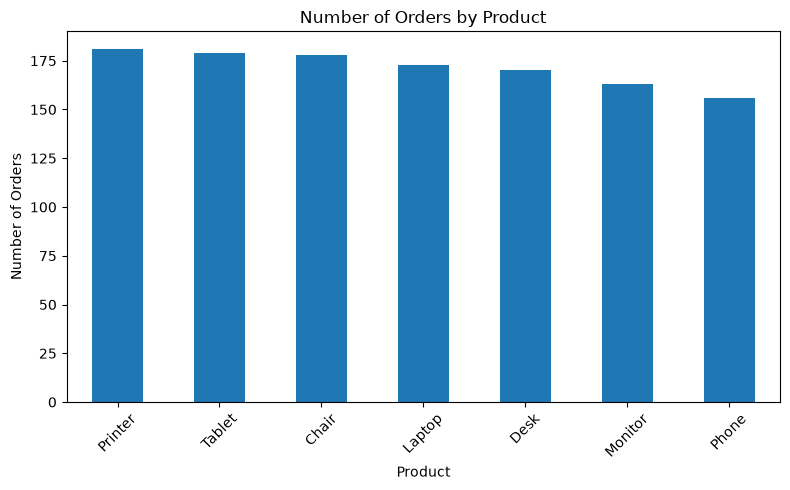

In [13]:
# Bar chart - Orders by Product

import matplotlib.pyplot as plt

product_counts = df['Product'].value_counts()

plt.figure(figsize=(8,5))
product_counts.plot(kind='bar')
plt.title('Number of Orders by Product')
plt.xlabel('Product')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('Charts/orders_by_product.png')
plt.show()

In [14]:
# Count orders by payment method

payment_counts = df['PaymentMethod'].value_counts()

print(payment_counts)

PaymentMethod
Online         258
Cash           246
Credit Card    234
Debit Card     232
Gift Card      230
Name: count, dtype: int64


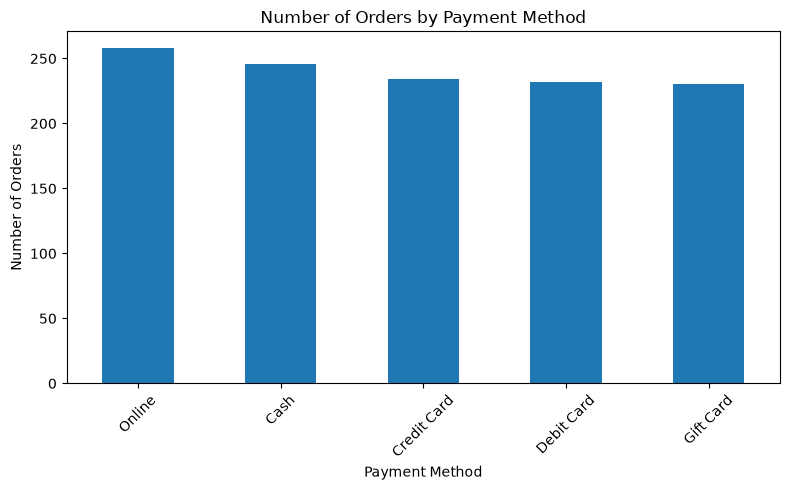

In [15]:
# Bar chart - Orders by Payment Method

plt.figure(figsize=(8, 5))

payment_counts.plot(kind='bar')

plt.title('Number of Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig('Charts/orders_by_payment_method.png')
plt.show()

In [16]:
# Count orders by order status
status_counts = df['OrderStatus'].value_counts()

print(status_counts)

OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64


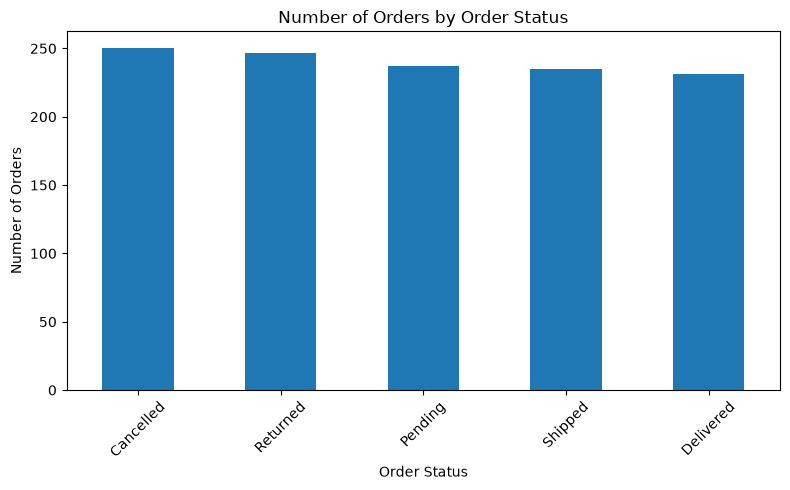

In [17]:
# Bar chart - Orders by Order Status

status_counts.plot(kind='bar', figsize=(8,5))

plt.title('Number of Orders by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig('Charts/orders_by_order_status.png')
plt.show()

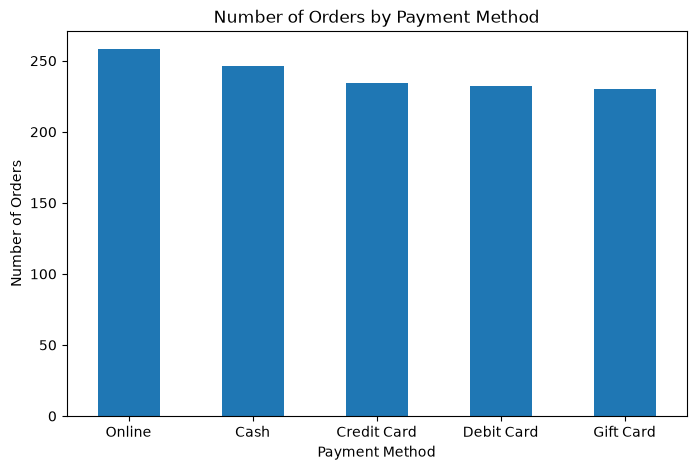

In [18]:
# Bar chart - Orders by Payment Method

payment_counts = df['PaymentMethod'].value_counts()

plt.figure(figsize=(8,5))
payment_counts.plot(kind='bar')

plt.title('Number of Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

plt.show()

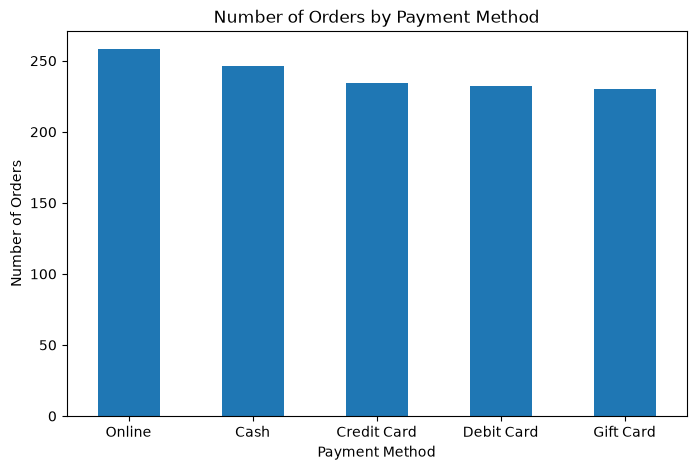

In [18]:
# Bar chart - Orders by Payment Method

payment_counts = df['PaymentMethod'].value_counts()

plt.figure(figsize=(8,5))
payment_counts.plot(kind='bar')

plt.title('Number of Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

plt.show()

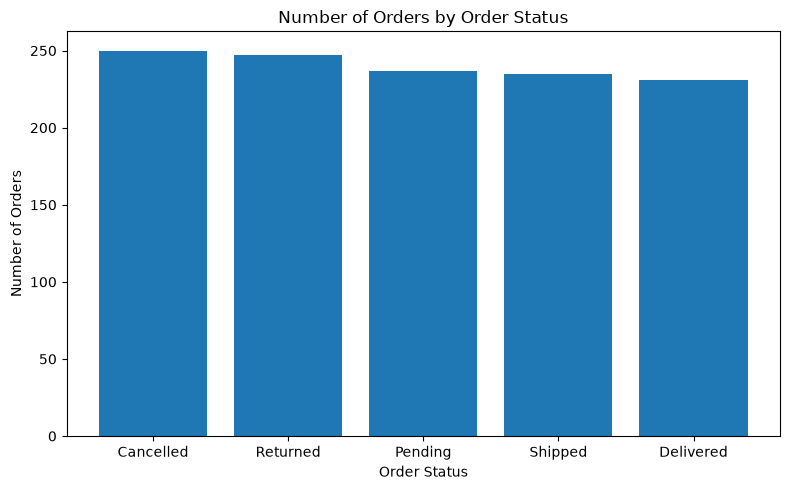

In [6]:
# Bar chart - Orders by Order Status

order_status_counts = df['OrderStatus'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(order_status_counts.index, order_status_counts.values)

plt.title('Number of Orders by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('charts/orders_by_order_status.png')

plt.show()

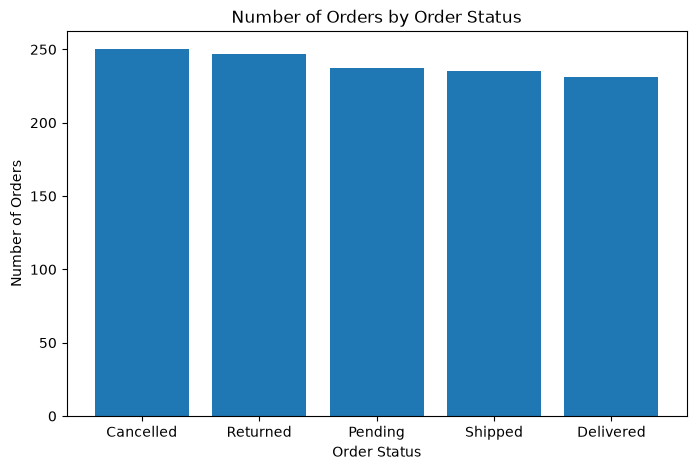

In [20]:
# Bar chart - Orders by Order Status

order_status_counts = df['OrderStatus'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(order_status_counts.index, order_status_counts.values)

plt.title('Number of Orders by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

plt.show()

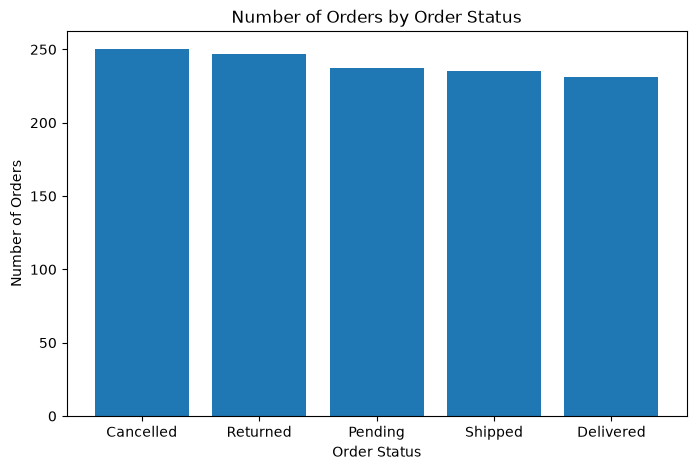

In [21]:
# Bar chart - Orders by Order Status

order_status_counts = df['OrderStatus'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(order_status_counts.index, order_status_counts.values)

plt.title('Number of Orders by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

plt.show()

In [19]:
# Total sales by product
product_sales = df.groupby('Product')['TotalPrice'].sum().sort_values(ascending=False)

print(product_sales)

Product
Chair      195620.11
Printer    195612.61
Laptop     192126.56
Tablet     186568.95
Monitor    175651.41
Desk       167459.93
Phone      151722.39
Name: TotalPrice, dtype: float64


In [20]:
# Total sales by order status
status_sales = df.groupby('OrderStatus')['TotalPrice'].sum().sort_values(ascending=False)

print(status_sales)

OrderStatus
Cancelled    276396.21
Pending      256328.15
Shipped      246159.58
Returned     243277.70
Delivered    242600.32
Name: TotalPrice, dtype: float64


In [21]:
# Total sales by payment method
payment_sales = df.groupby('PaymentMethod')['TotalPrice'].sum().sort_values(ascending=False)

print(payment_sales)

PaymentMethod
Credit Card    263847.63
Online         262442.94
Cash           259786.29
Gift Card      246323.92
Debit Card     232361.18
Name: TotalPrice, dtype: float64


In [22]:
# Total sales by payment method
payment_sales = df.groupby('PaymentMethod')['TotalPrice'].sum().sort_values(ascending=False)

print(payment_sales)

PaymentMethod
Credit Card    263847.63
Online         262442.94
Cash           259786.29
Gift Card      246323.92
Debit Card     232361.18
Name: TotalPrice, dtype: float64


In [23]:
# Total sales by order status
status_sales = df.groupby('OrderStatus')['TotalPrice'].sum().sort_values(ascending=False)

print(status_sales)

OrderStatus
Cancelled    276396.21
Pending      256328.15
Shipped      246159.58
Returned     243277.70
Delivered    242600.32
Name: TotalPrice, dtype: float64


In [24]:
print(df.columns.tolist())

['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice', 'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber', 'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice']


In [25]:
# Check column names
print(df.columns.tolist())

['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice', 'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber', 'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice']


In [26]:
for i, col in enumerate(df.columns):
    print(i, ":", col)

0 : OrderID
1 : Date
2 : CustomerID
3 : Product
4 : Quantity
5 : UnitPrice
6 : ShippingAddress
7 : PaymentMethod
8 : OrderStatus
9 : TrackingNumber
10 : ItemsInCart
11 : CouponCode
12 : ReferralSource
13 : TotalPrice


In [27]:
# Total sales by product

product_sales = df.groupby('Product')['TotalPrice'].sum().sort_values(ascending=False)

print(product_sales)

Product
Chair      195620.11
Printer    195612.61
Laptop     192126.56
Tablet     186568.95
Monitor    175651.41
Desk       167459.93
Phone      151722.39
Name: TotalPrice, dtype: float64


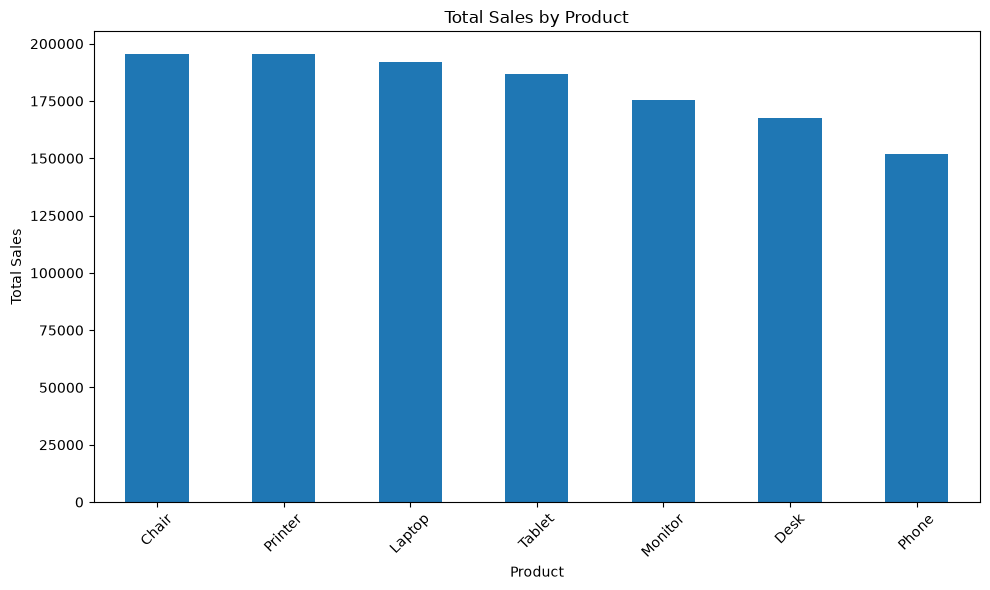

In [28]:
# Bar chart - Total sales by product

product_sales.plot(kind='bar', figsize=(10, 6))

plt.title('Total Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# Number of orders by product

order_count = df['Product'].value_counts()

print(order_count)

Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64


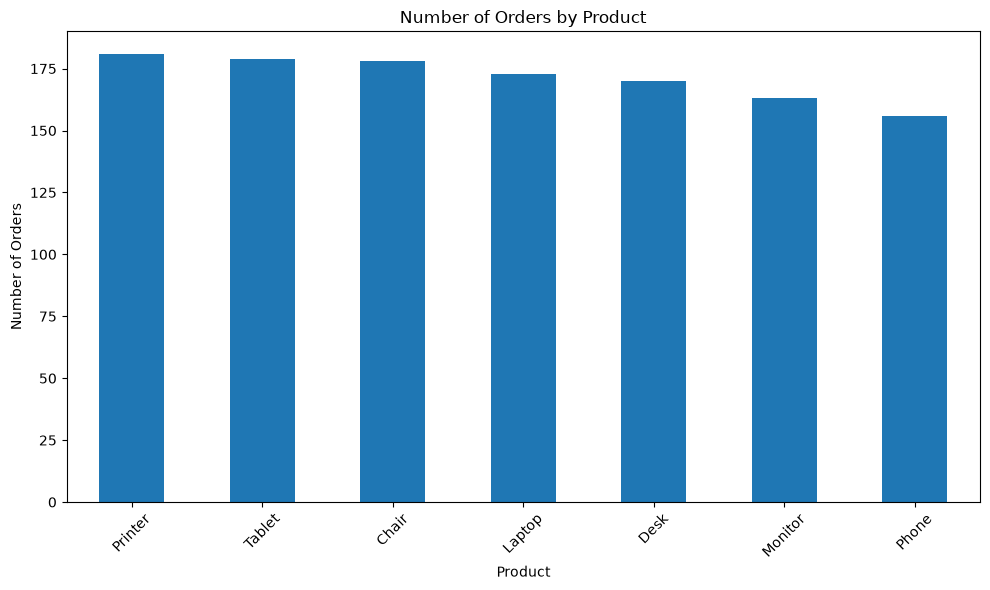

In [30]:
# Bar chart - Number of orders by product

order_count.plot(kind='bar', figsize=(10, 6))

plt.title('Number of Orders by Product')
plt.xlabel('Product')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Total sales by referral source

referral_sales = df.groupby('ReferralSource')['TotalPrice'].sum().sort_values(ascending=False)

print(referral_sales)

ReferralSource
Instagram    275285.45
Email        261808.55
Google       250441.48
Facebook     250410.90
Referral     226815.58
Name: TotalPrice, dtype: float64


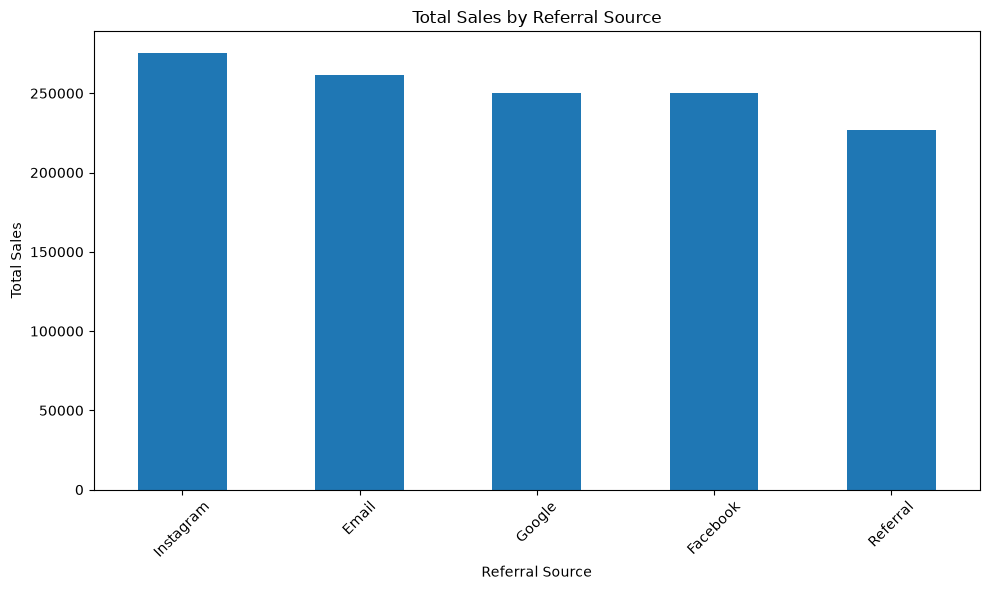

In [32]:
# Bar chart - Total sales by referral source

referral_sales.plot(kind='bar', figsize=(10, 6))

plt.title('Total Sales by Referral Source')
plt.xlabel('Referral Source')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# Basic statistics for TotalPrice

print("Mean Sales:", df['TotalPrice'].mean())
print("Median Sales:", df['TotalPrice'].median())
print("Total Orders:", df['OrderID'].count())

Mean Sales: 1053.9683
Median Sales: 823.615
Total Orders: 1200


In [34]:
# Basic statistics for Quantity

print("Mean Quantity:", df['Quantity'].mean())
print("Median Quantity:", df['Quantity'].median())
print("Total Quantity:", df['Quantity'].sum())

Mean Quantity: 2.9458333333333333
Median Quantity: 3.0
Total Quantity: 3535


In [35]:
# Check for outliers in TotalPrice

Q1 = df['TotalPrice'].quantile(0.25)
Q3 = df['TotalPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['TotalPrice'] < lower_limit) |
    (df['TotalPrice'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Number of outliers:", len(outliers))

Q1: 410.52
Q3: 1578.475
IQR: 1167.955
Number of outliers: 8


In [36]:
# Display outliers
print(outliers[['OrderID', 'Product', 'Quantity', 'TotalPrice']])

        OrderID  Product  Quantity  TotalPrice
107   ORD200107  Printer         5     3353.75
326   ORD200326   Laptop         5     3352.40
328   ORD200328   Tablet         5     3370.20
469   ORD200469    Chair         5     3384.90
632   ORD200632   Laptop         5     3390.80
789   ORD200789   Tablet         5     3456.40
1065  ORD201065  Printer         5     3334.00
1122  ORD201122  Monitor         5     3390.95


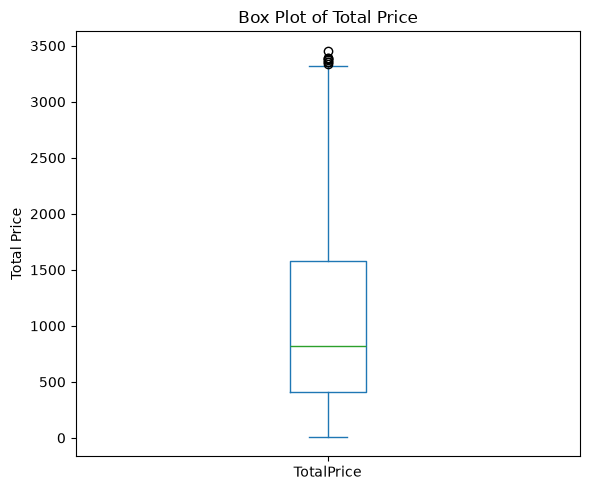

In [37]:
# Box plot for TotalPrice

df['TotalPrice'].plot(kind='box', figsize=(6, 5))

plt.title('Box Plot of Total Price')
plt.ylabel('Total Price')

plt.tight_layout()
plt.show()

In [38]:
# Correlation between numerical columns

correlation = df[['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice']].corr()

print(correlation)

             Quantity  UnitPrice  ItemsInCart  TotalPrice
Quantity     1.000000   0.014553     0.650061    0.615251
UnitPrice    0.014553   1.000000     0.000602    0.717081
ItemsInCart  0.650061   0.000602     1.000000    0.392540
TotalPrice   0.615251   0.717081     0.392540    1.000000


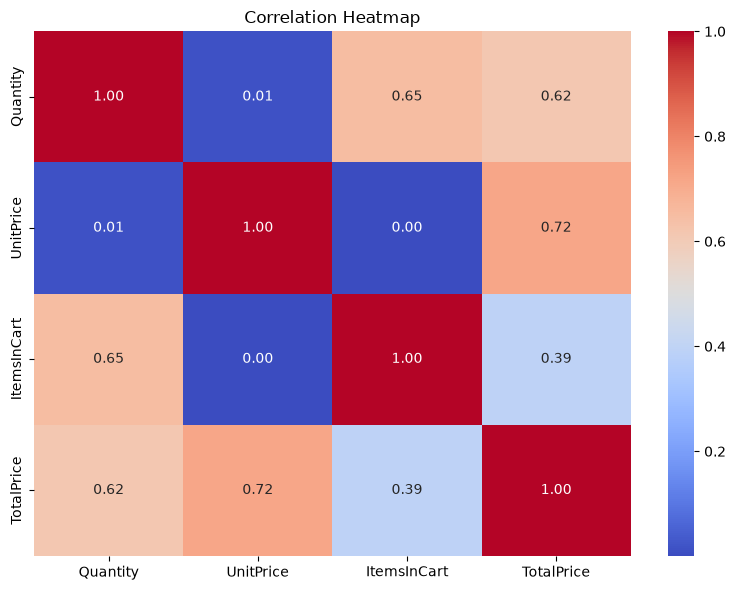

In [40]:
# Correlation heatmap

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('charts/correlation_heatmap.png')
plt.show()

# Key Observations and Insights

1. Chair generated the highest total sales, followed closely by Printer and Laptop.

2. Printer had the highest number of orders, while Phone had the lowest number of orders.

3. Instagram was the highest-performing referral source in terms of total sales.

4. Cancelled orders had the highest total sales value among all order statuses.

5. Credit Card generated the highest total sales among the payment methods.

6. The average TotalPrice was 1053.97, while the median was 823.62.

7. The average order quantity was approximately 2.95, with a total quantity of 3555.

8. The analysis identified 8 outliers in TotalPrice using the IQR method.

9. UnitPrice and TotalPrice showed the strongest positive correlation (0.72).

10. Quantity also had a positive correlation with TotalPrice (0.62).

11. ItemsInCart showed a moderate positive correlation with TotalPrice (0.39).

12. Correlation indicates association between variables and does not necessarily imply causation. 

# Conclusion

The Exploratory Data Analysis helped identify important patterns, trends, and outliers in the dataset. The analysis included descriptive statistics, product-wise orders, referral-source sales, outlier detection, and correlation analysis.

The results show that UnitPrice and Quantity have a strong positive relationship with TotalPrice. The analysis also identified 8 outliers in TotalPrice.

Overall, EDA provided useful insights into customer orders and sales performance and helped understand the important factors affecting TotalPrice.